# User Behavior & Monetization Regression Pipeline

This pipeline leverages a Random Forest architecture and advanced interpretability tools (SHAP, PDP) to evaluate user behavioral telemetry and its impact on revenue. It implements custom winsorization for outlier handling, a unique stable-mode heuristic for hyperparameter selection, and rigorous non-parametric statistical diagnostics (Cohen's d, KS-Test) to map behavioral cohorts directly to monetization scale.



In [1]:
import pandas as pd
import numpy as np
from statistics import mean
from scipy.stats import ks_2samp

# Visualization libraries
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt

# Custom project modules
import regression_model_setup as rms

# Configure environment settings
rms.apply_theme()

# Project configurations
target = 'revenue'


In [2]:
# Load the synthetic player behavior dataset
results_df = pd.read_csv('synthetic_users.csv')

# Drop identifier and categorical columns not used in the regression model
results_df = results_df.drop(columns=['player_id', 'segment'], errors='ignore')

# Impute missing values with 0 to prevent issues during model training
results_df = results_df.fillna(0)

# Display the prepared dataframe
results_df


,revenue,feature_A,feature_B,feature_C,f_neutral_1,f_neutral_2,f_neutral_3
0,0.112984,231.0,1482.0,1773.0,0.797903,0.159682,0.298777
1,1.853651,69.0,1682.0,1684.0,0.959326,0.745312,0.342203
2,1.217135,261.0,1178.0,1367.0,0.518735,0.072726,0.174626
3,0.999441,137.0,1338.0,1095.0,0.302235,0.880557,0.705730
4,1.303194,109.0,1650.0,547.0,0.981310,0.525359,0.394562
...,...,...,...,...,...,...,...
9995,1.072332,75.0,1495.0,819.0,0.524016,0.649930,0.242501
9996,2.378438,98.0,953.0,316.0,0.596799,0.206719,0.997439
9997,0.954210,202.0,263.0,145.0,0.788424,0.576036,0.139574
9998,1.304638,44.0,1951.0,1586.0,0.804460,0.451873,0.582693


In [3]:
results_df.columns

Index(['revenue', 'feature_A', 'feature_B', 'feature_C', 'f_neutral_1',
       'f_neutral_2', 'f_neutral_3'],
      dtype='object')

In [4]:
# Create a deep copy of the dataframe to protect the baseline data
data = results_df.copy()

# Generate and display a comprehensive distribution summary for all features
stats_summary = rms.analyze_multiple_stats(data)
stats_summary


,Feature,Min,Max,Mean,Median,25th Percentile,75th Percentile,95th Percentile,99th Percentile,999th Percentile
0,revenue,0.008129,68.111984,2.290726,0.926966,0.516792,1.578970,8.603044,32.599881,52.804512
1,feature_A,0.000000,498955.000000,15013.264400,164.000000,81.000000,247.000000,51015.450000,395478.740000,481647.118000
2,feature_B,0.000000,499766.000000,19481.435600,1115.000000,560.750000,1667.250000,157054.350000,395399.980000,492995.018000
3,feature_C,0.000000,498924.000000,14406.187400,1014.000000,457.000000,1566.000000,51283.350000,402519.720000,483960.314000
4,f_neutral_1,0.000057,0.999994,0.499325,0.499480,0.249898,0.746698,0.948766,0.988572,0.998851
5,f_neutral_2,0.000013,0.999660,0.504783,0.505524,0.259619,0.757271,0.950554,0.989676,0.998436
6,f_neutral_3,0.000157,0.999952,0.499022,0.501205,0.247487,0.743256,0.949185,0.989828,0.999132


In [5]:
# Cap extreme values at the 0.1% and 99.9% percentiles to handle outliers
data_wins = rms.winsorize_df(data, lower=0.001, upper=0.999)

# Store a copy of the winsorized dataset for downstream feature modeling
data_meta = data_wins.copy()


In [6]:
# Verify the impact of winsorization by re-generating summary statistics
stats_summary_wins = rms.analyze_multiple_stats(data_wins)
stats_summary_wins


,Feature,Min,Max,Mean,Median,25th Percentile,75th Percentile,95th Percentile,99th Percentile,999th Percentile
0,revenue,0.027235,52.804512,2.285265,0.926966,0.516792,1.578970,8.603044,32.599881,52.804299
1,feature_A,0.000000,481647.118000,15005.329818,164.000000,81.000000,247.000000,51015.450000,395478.740000,481647.000118
2,feature_B,3.000000,492995.018000,19477.572818,1115.000000,560.750000,1667.250000,157054.350000,395399.980000,492994.001018
3,feature_C,0.000000,483960.314000,14399.790814,1014.000000,457.000000,1566.000000,51283.350000,402519.720000,483960.000314
4,f_neutral_1,0.000471,0.998851,0.499325,0.499480,0.249898,0.746698,0.948766,0.988572,0.998851
5,f_neutral_2,0.000957,0.998436,0.504783,0.505524,0.259619,0.757271,0.950554,0.989676,0.998436
6,f_neutral_3,0.001350,0.999132,0.499023,0.501205,0.247487,0.743256,0.949185,0.989828,0.999132


In [7]:
# Execute a baseline Random Forest model screening to gauge initial feature utility
rmse_train, rmse_test, r2_train, r2_test = rms.quick_rf_screening(data_wins, target=target)


Train RMSE: 1.02, R²: 0.97
Test RMSE: 2.59, R²: 0.77


In [8]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# NOTE ON METHODOLOGY: 
# This tuning strategy filters for stable iterations (positive test R² and minor generalization gaps).
# It then extracts the statistical mode of each hyperparameter across these stable runs to construct a robust setup.

# Define hyperparameter search grid for random forest evaluation
param_grid_rf = {
    'n_estimators': [50, 100, 200, 300, 500],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', 0.3, 0.5, 0.8],
    'bootstrap': [True, False]
}


# Separate the dataset into independent features and dependent target
model = data_wins.copy()
X_full = model.drop(columns=[target])
y_full = model[target]

# Execute custom randomized meta-tuning over the search space
df_results = rms.meta_tuning(
    X_full=X_full,
    y_full=y_full,
    model_class=RandomForestRegressor,
    param_grid=param_grid_rf,
    n_iterations=20,       # Production default: 50 iterations (reduced here for fast testing)
    sample_size=100        # Production default: 1000 samples (reduced here for fast testing)
)

# Filter results for positive test R² and minor generalization gaps (< 0.2 difference)
filtered_df = df_results[
    (df_results['test_r2'] > 0) &
    (abs(df_results['train_r2'] - df_results['test_r2']) < 0.2)
]

# Calculate the statistical mode across stable parameter choices
summary_df = filtered_df.drop(columns=['iteration', 'train_r2', 'test_r2']).mode().iloc[0].to_frame(name='Most Common Value')
best_params = summary_df["Most Common Value"].to_dict()

# Safe type casting: convert exact whole numbers to int, preserve floats like 0.3 or 0.5
for key, value in best_params.items(): 
    if isinstance(value, float):
        if value.is_integer():
            best_params[key] = int(value)
    elif isinstance(value, (int, np.integer)) and not isinstance(value, bool):
        best_params[key] = int(value)

# Inject standard random state for total pipeline reproducibility
best_params.update({ 'random_state': 42 })
best_params


{'n_estimators': 50,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 0.5,
 'max_depth': 20,
 'bootstrap': False,
 'random_state': 42}

In [11]:
# rmse_train, rmse_test, r2_train, r2_test = rms.final_model(model,target=target, rf_params=best_params)

In [9]:
# Isolate features and target variables for the final model training phase
model = data_wins.copy()
X_full = model.drop(columns=[target])
y_full = model[target]

# Hardcode the optimal hyperparameter values found during meta-tuning 
# This prevents re-running the expensive search process on every execution
best_params = {
    'n_estimators': 50,
    'min_samples_split': 2,
    'min_samples_leaf': 1,
    'max_features': 0.5,
    'max_depth': 20,
    'bootstrap': False,
    'random_state': 42
}

best_params


{'n_estimators': 50,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_features': 0.5,
 'max_depth': 20,
 'bootstrap': False,
 'random_state': 42}

In [10]:
# Train the final optimized Random Forest Regressor and evaluate performance
rmse_train, rmse_test, r2_train, r2_test = rms.final_model(
    model, 
    target=target, 
    rf_params=best_params
)


Train RMSE: 0.51, R²: 0.99
Test RMSE: 2.64, R²: 0.76


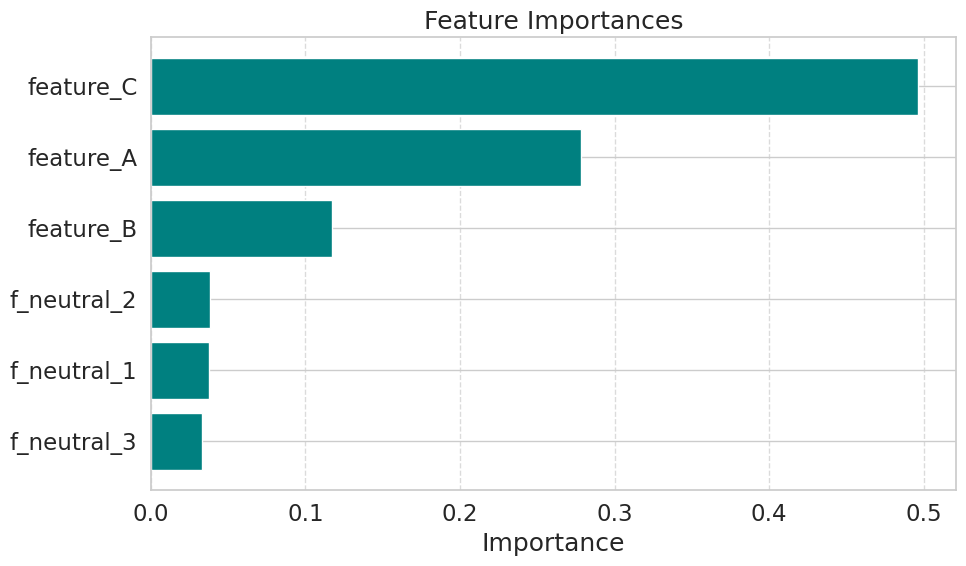

In [11]:
import os

# Convert feature columns to a clean list structure
feature_names = X_full.columns.tolist()

# Define export directory paths if you want to save artifacts
# export_dir = "./outputs"
# save_path = os.path.join(export_dir, "feature_importances.jpeg")

# Generate and display the feature importance chart
df_importance = rms.plot_feature_importances(
    X=X_full,
    y=y_full,
    feature_names=feature_names,
    best_params=best_params,
    max_features=15,
    # save_path=save_path  
)


In [12]:
# Generate a clean tabular breakdown of the top 15 most influential features
df_importance_table = rms.get_feature_importance_table(
    X=X_full,
    y=y_full,
    feature_names=feature_names,
    best_params=best_params,
    top_n=15
)

# Display the sorted tabular results directly in the notebook execution window
df_importance_table


,feature,importance
2,feature_C,0.495952
0,feature_A,0.278270
1,feature_B,0.116878
4,f_neutral_2,0.038318
3,f_neutral_1,0.037436
5,f_neutral_3,0.033146


In [13]:
# ==============================================================================
# STATISTICAL PROFILE ANALYSIS CRITERIA Cheat Sheet (For Code Reviews & Interviews):
#
# 1. Mean Revenue Ratio: 
#    - HIGH VALUE: Substantial financial multiplier (e.g., 5.0x means this cohort spends 5x the average).
#
# 2. Cohen's d (Magnitude of Difference): 
#    - HIGH VALUE (> 0.80): Massive separation; this behavior strictly segments spenders.
#    - LOW VALUE (< 0.20): Negligible effect; doing this behavior doesn't materially shift spend scales.
#
# 3. KS Statistic (Structural Distance between Distribution Curves): 
#    - HIGH VALUE (Closer to 1): The groups represent completely unique spending archetypes.
#    - LOW VALUE (Closer to 0): Heavy distribution overlap; behavior profiles share the same spend curve.
#
# 4. KS p-value (Statistical Confidence / Signficance): 
#    - LOW VALUE (< 0.05): Rejects the null hypothesis; proves the group difference is real and not a fluke.
#    - HIGH VALUE (> 0.05): Statistically weak; variations are likely noise.
# ==============================================================================

# Measure the statistical distance and effect sizes for players in the 95th percentile of behaviors
summary_df = rms.analyze_multiple_by_quantile(
    data=data_meta, 
    columns=feature_names,  
    target_col=target, 
    quantile=0.95
)

# Sort metrics descending based on how drastically high-usage cohorts multiply average spend
summary_df = summary_df.sort_values(by=['Mean Revenue Ratio'], ascending=False)

# Display statistical profile mapping data
summary_df


,Feature,Target Column,Mean Revenue Ratio,Cohen's d Effect Size,KS Statistic,KS p-value
1,feature_B,revenue,4.57,0.80,0.65,0.0000
0,feature_A,revenue,1.81,0.40,0.59,0.0000
2,feature_C,revenue,1.81,0.40,0.59,0.0000
4,f_neutral_2,revenue,1.01,0.01,0.05,0.2325
3,f_neutral_1,revenue,1.00,0.00,0.05,0.1680
5,f_neutral_3,revenue,0.94,-0.02,0.03,0.7935


In [14]:
# Generate final descriptive validation stats across your chosen feature list
stats_summary_meta = rms.analyze_multiple_stats(data_meta, columns=feature_names)
stats_summary_meta


,Feature,Min,Max,Mean,Median,25th Percentile,75th Percentile,95th Percentile,99th Percentile,999th Percentile
0,feature_A,0.000000,481647.118000,15005.329818,164.000000,81.000000,247.000000,51015.450000,395478.740000,481647.000118
1,feature_B,3.000000,492995.018000,19477.572818,1115.000000,560.750000,1667.250000,157054.350000,395399.980000,492994.001018
2,feature_C,0.000000,483960.314000,14399.790814,1014.000000,457.000000,1566.000000,51283.350000,402519.720000,483960.000314
3,f_neutral_1,0.000471,0.998851,0.499325,0.499480,0.249898,0.746698,0.948766,0.988572,0.998851
4,f_neutral_2,0.000957,0.998436,0.504783,0.505524,0.259619,0.757271,0.950554,0.989676,0.998436
5,f_neutral_3,0.001350,0.999132,0.499023,0.501205,0.247487,0.743256,0.949185,0.989828,0.999132


------------------------------------------------------------------

# **Partial Dependence** 

Model fit RMSE of Random Forest Regressor: 0.48
Model fit R² score of Random Forest Regressor: 0.9927


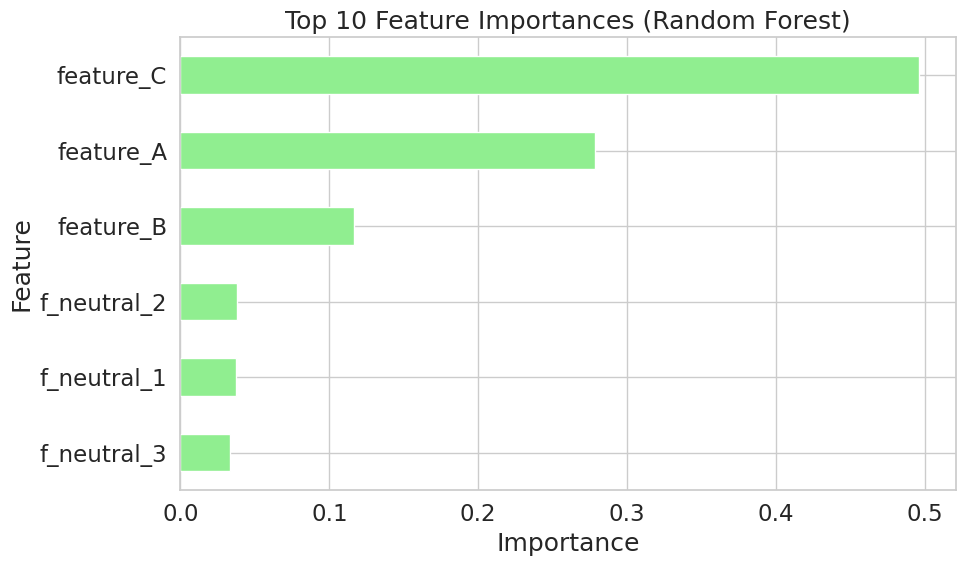

In [15]:
# ==============================================================================
# PIPELINE ARCHITECTURE NOTE:
# We fit the model on the full dataset here to generate robust, population-wide 
# parameters. This ensures our subsequent Partial Dependence Plots (PDPs) capture 
# maximum behavioral variance without being clipped by a data split.
# ==============================================================================

# Execute the complete training and visual evaluation pipeline for the final model
rf_model, importances_rf, rmse_rf, r2_rf, features, revenue = rms.run_random_forest_analysis(
    model_df=model,
    target_col=target,
    best_params=best_params,
    top_n=10
)


Model fit RMSE of Random Forest Regressor: 0.48
Model fit R² score of Random Forest Regressor: 0.9927


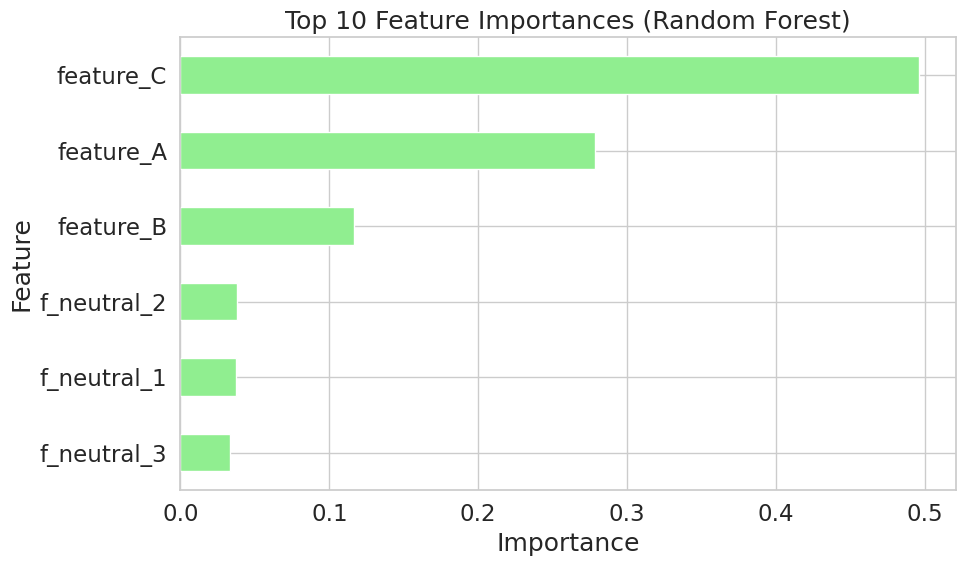

In [16]:
rf_model, importances_rf, rmse_rf, r2_rf, features, revenue = rms.run_random_forest_analysis(
    model_df=model.copy(),
    target_col=target,
    best_params=best_params,
    top_n=10
)

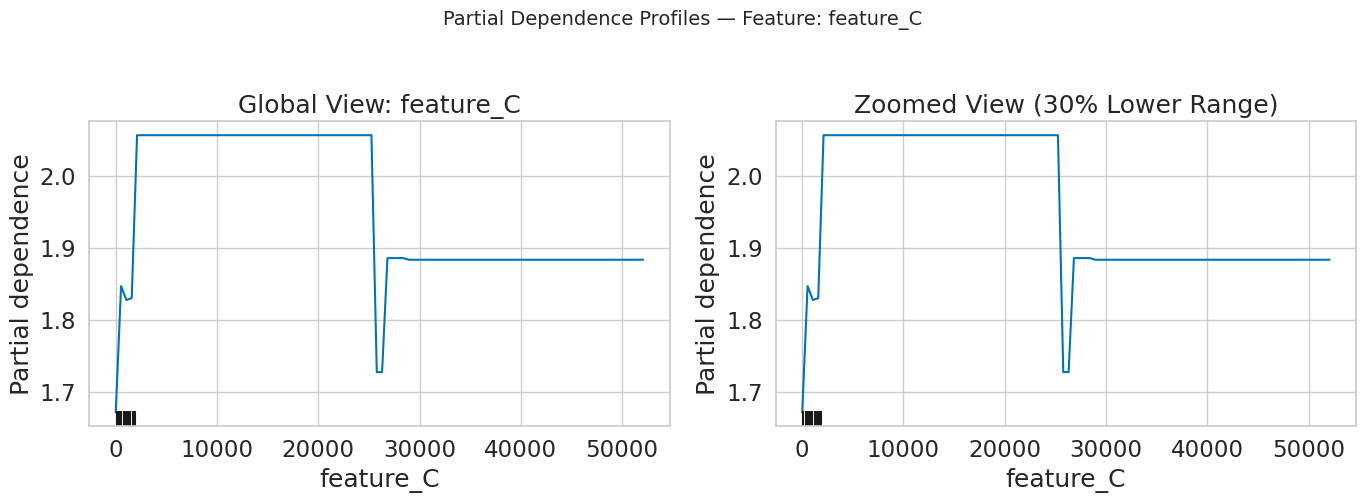

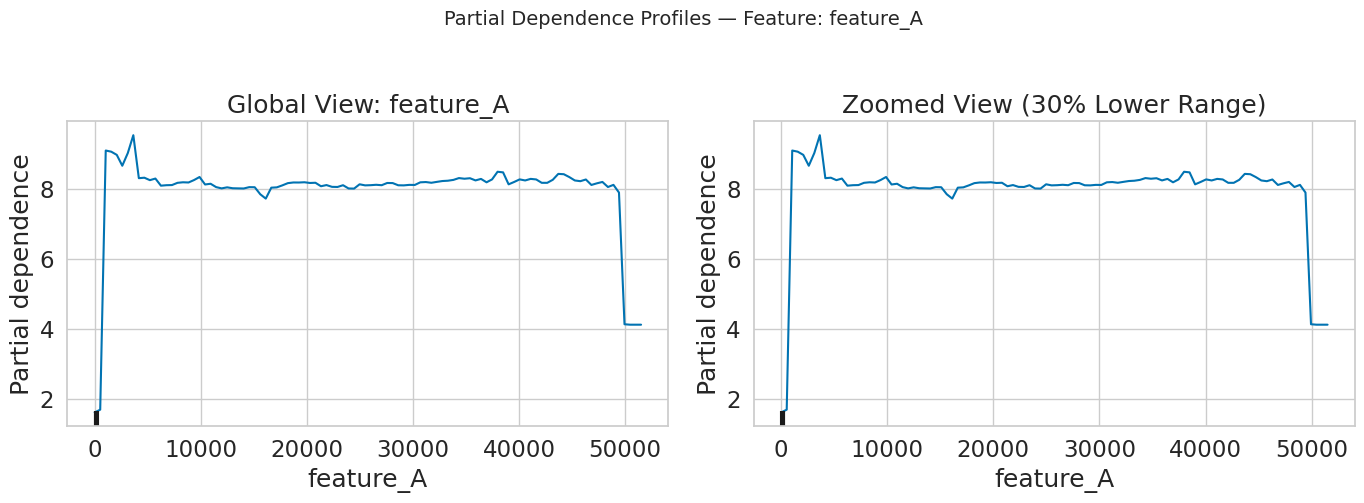

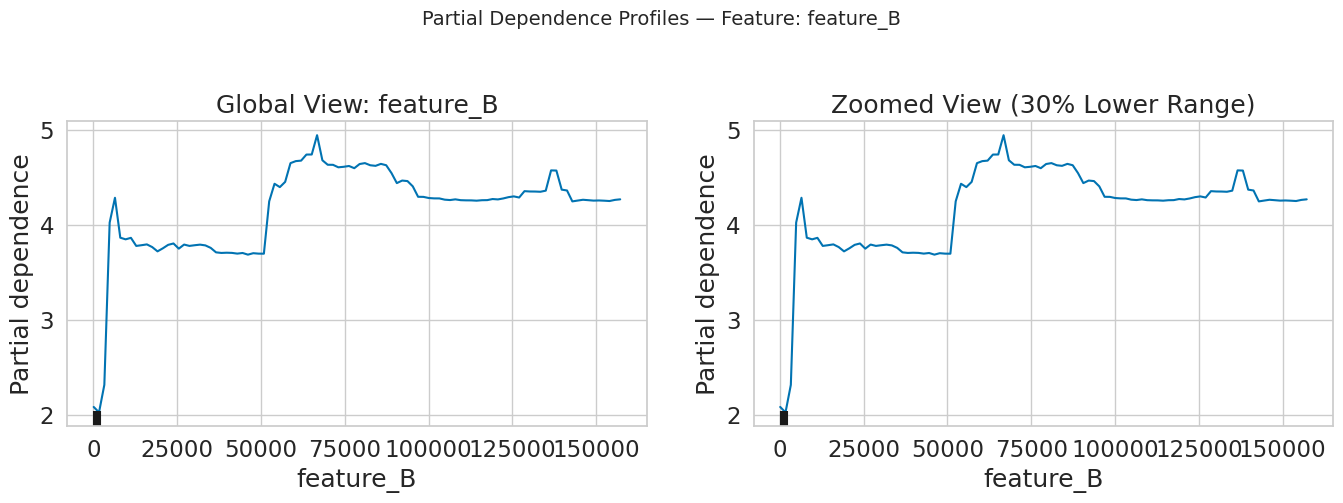

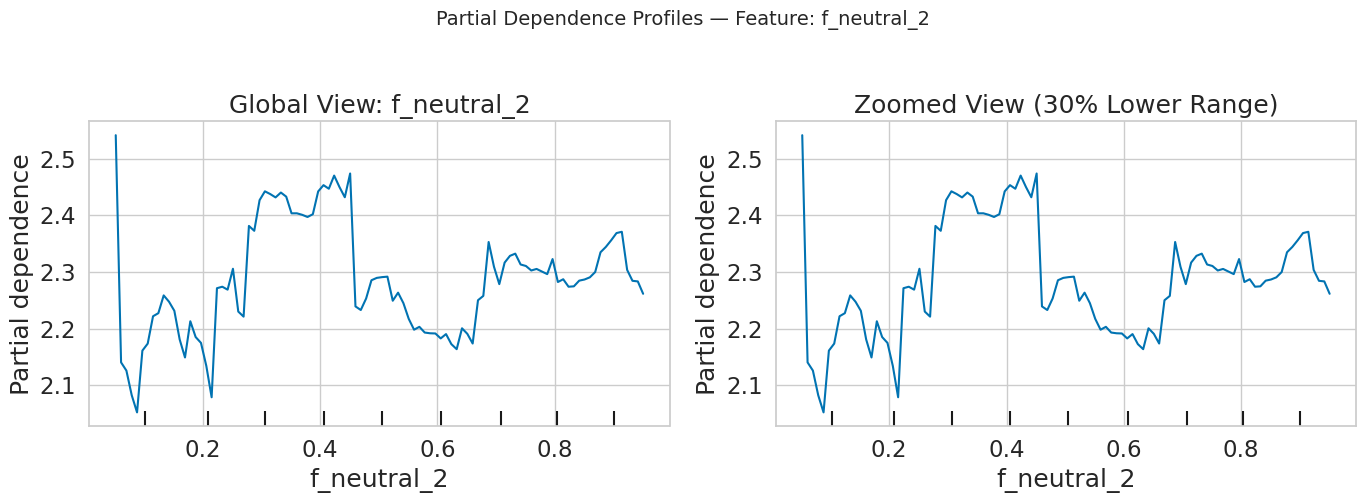

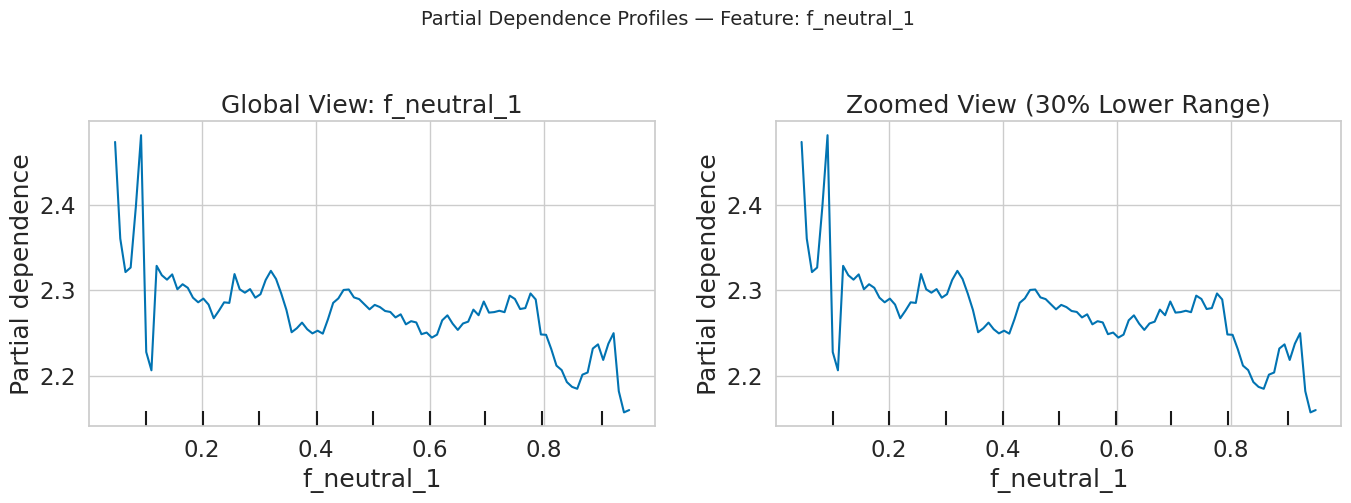

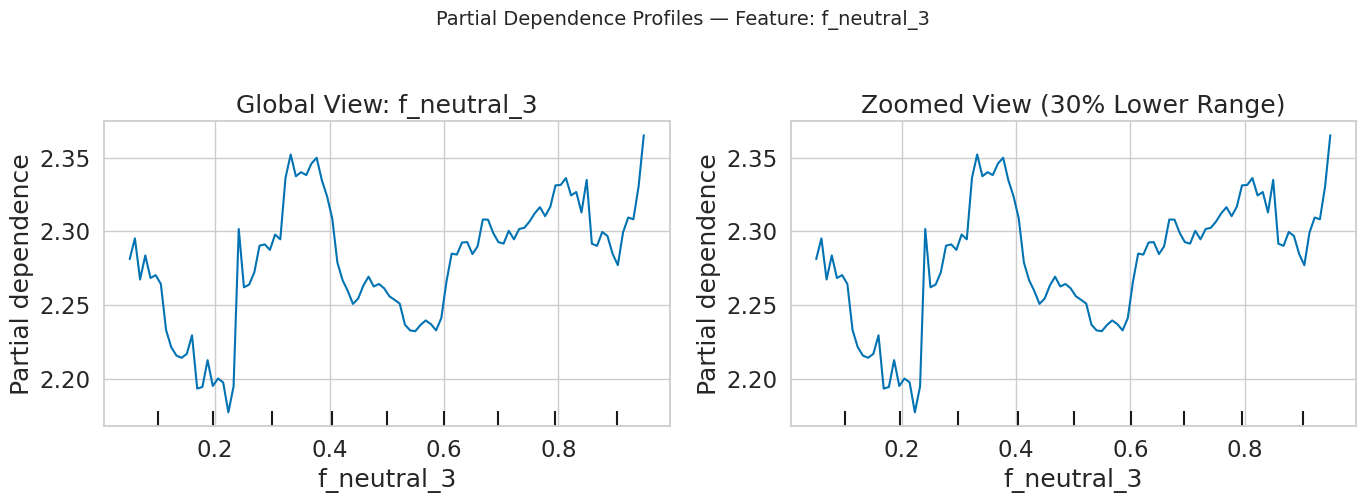

In [17]:

# Generate vector-sharp partial dependence dashboards comparing broad and zoomed trends
rms.plot_partial_dependence_grid(
    model=rf_model,         
    features=features,      
    importances=importances_rf,  
    run_id="run_1",              
    top_n=6,                     
    zoom_fraction=0.3           
)


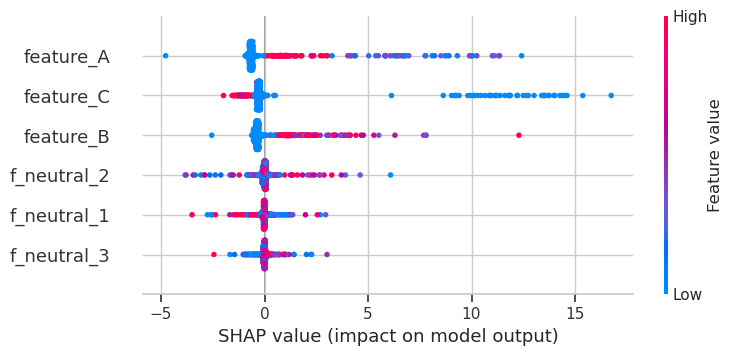

In [21]:
import shap

# ==============================================================================
# SHAP EXPLANATION METHODOLOGY NOTES (For Code Reviews & Technical Interviews):
# 1. SHAP Values calculate the marginal contribution of each behavior feature 
#    to a player's final revenue prediction using cooperative game theory.
# 2. Row Ordering: Features are automatically ranked top-to-bottom by global impact.
# 3. Horizontal Spread: Quantifies how intensely a feature pushes predictions higher or lower.
# 4. Color Mapping: Red indicates high feature values (frequent activity), while 
#    Blue indicates low feature values (infrequent activity).
# ==============================================================================

# Extract a representative slice of player profiles to optimize SHAP computation time
X_sample = features.sample(1000, random_state=42)

# Initialize a tree-optimized explainer mapped to our trained Random Forest architecture
explainer = shap.TreeExplainer(rf_model)

# Compute feature attribution values for our sampled population matrix
shap_values = explainer.shap_values(X_sample)

# Generate the global beeswarm summary plot showing behavior-to-revenue directionality
# Note: In modern SHAP versions, shap.summary_plot defaults to a clean beeswarm visualization
shap.summary_plot(shap_values, X_sample)


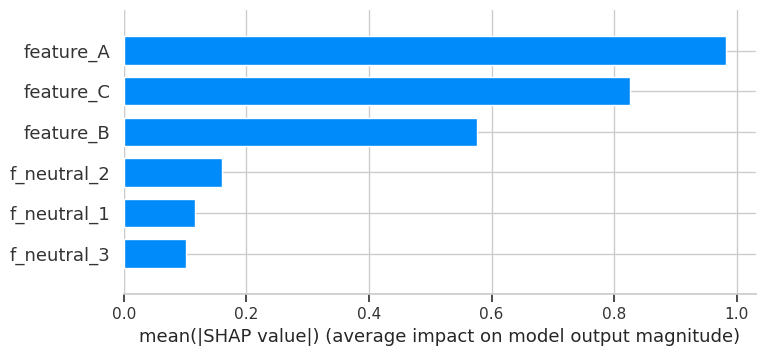

In [22]:
# ==============================================================================
# SHAP GLOBAL SCALE ANALYSIS NOTES:
# - This bar plot measures the mean absolute value of the SHAP attributions.
# - Unlike the beeswarm plot, this chart focuses strictly on the overall magnitude
#   of importance, filtering out the positive/negative directionality.
# - It provides a highly stable, mathematically robust baseline to verify 
#   our initial Random Forest feature importances.
# ==============================================================================

# Generate the global absolute feature impact chart using the sampled data profile
shap.summary_plot(shap_values, X_sample, plot_type="bar")


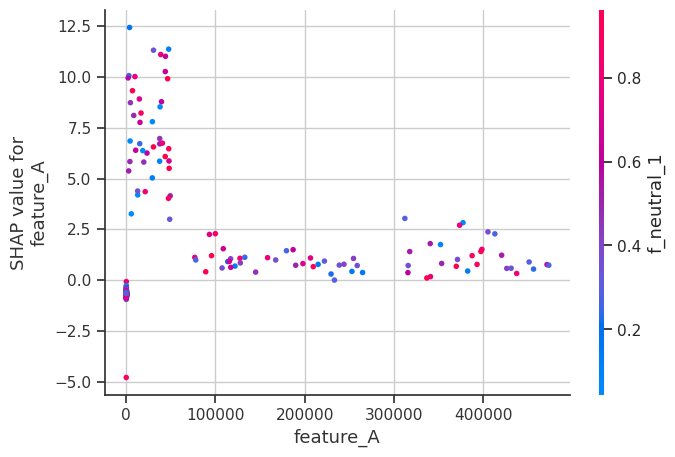

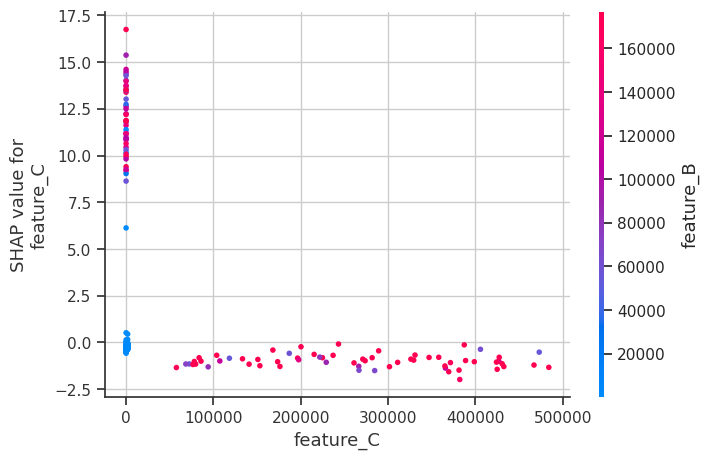

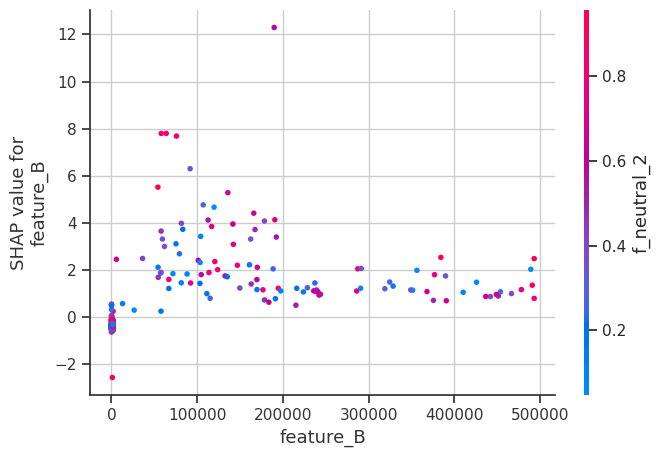

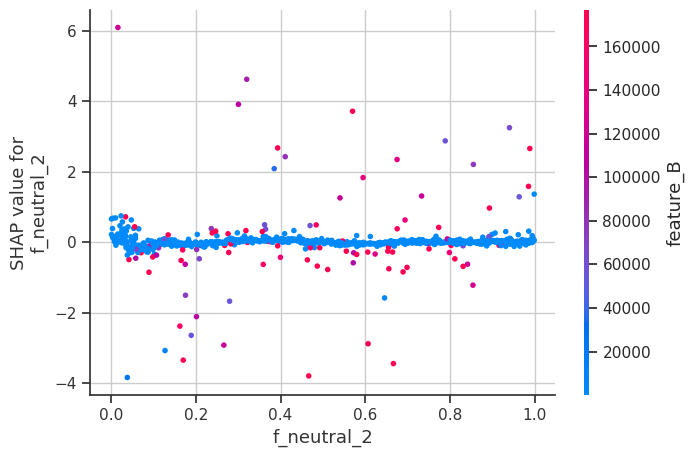

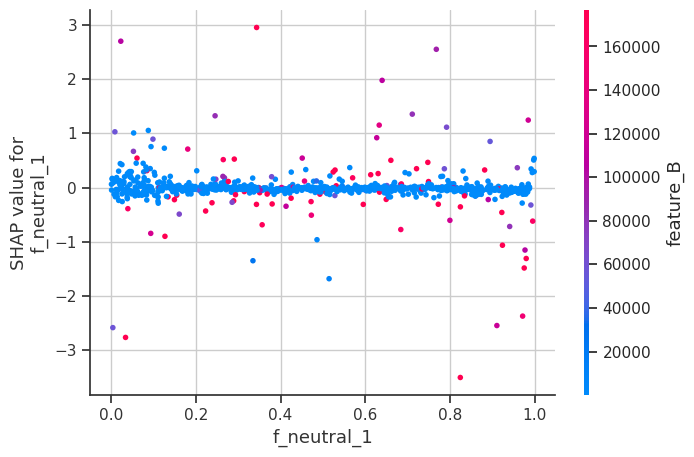

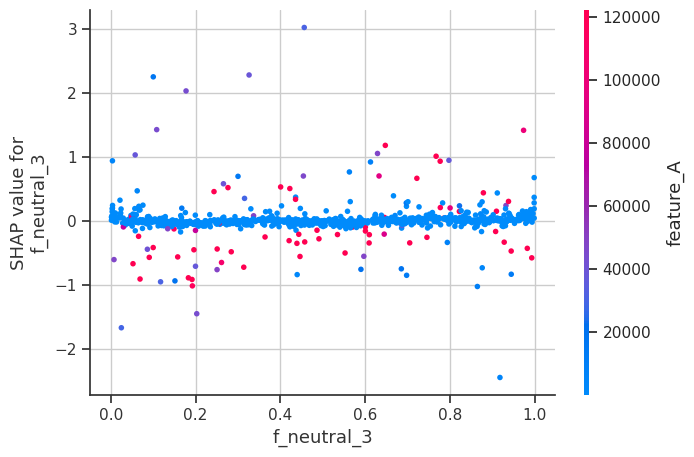

In [23]:
# ==============================================================================
# SHAP DEPENDENCE PLOT METHODOLOGY NOTES:
# 1. Displays the relationship between a single behavior's actual scale (X-axis) 
#    and its true marginal attribution to predicted revenue (Y-axis).
# 2. Vertical Dispersion: If dots spread out vertically for the same X value, 
#    it visually proves that an interaction effect is taking place.
# 3. Automatic Interactions: SHAP automatically identifies the strongest interacting 
#    feature and highlights it using the color scale to map out joint behaviors.
# ==============================================================================

# Extract the sorted order of top global features from the SHAP sample to focus our analysis
top_shap_features = np.abs(shap_values).mean(0).argsort()[::-1]
top_feature_names = [X_sample.columns[i] for i in top_shap_features]

# Generate dependency profiles only for the top 6 most impactful behaviors to keep the notebook readable
for feature in top_feature_names[:6]:
    # Corrected target data matrix to X_sample to perfectly match shap_values array dimensions
    shap.dependence_plot(feature, shap_values, X_sample)
